# 🚀 TriP: Triple-Prompt Framework in Continual Graph Learning
### *Aligning Pre-training and Class-Incremental Objectives in Continual Graph Learning*
*(Neural Networks Journal, Elsevier)*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Abhireddy28/TriP-Continual-Graph-Learning/blob/main/notebooks/TriP_Colab_Runner.ipynb)

---
### **Overview of Key TriP Components:**
1. **Self-Supervised Pre-training:** Trains GNN backbone on Task 1 with random edge dropout & feature masking, then **permanently freezes** it.
2. **Feature Prompt (GPF-plus):** $\hat{\mathbf{x}}_v = \mathbf{x}_v + \mathbf{p}_v$ adapts the graph node feature space.
3. **Class Prompt:** Feature-wise gating $\tilde{\mathbf{h}}_v = \mathbf{h}_v \odot \mathbf{q}_t^{cls}$ enhances category separability.
4. **Unified Prompt Template:** Aligns downstream continual classification with prototype-based contrastive loss (Eq. 9-14).
5. **Zero-forgetting Task Querying:** Queries test graphs against task prototypes $\mathbf{m}_t$ to select prompts without ground-truth task labels.

## 🛠️ Step 1: Environment Setup & GPU Check
Ensure you have a GPU runtime enabled (`Runtime` > `Change runtime type` > `T4 GPU`).

In [1]:
!nvidia-smi
import torch
print(f"CUDA Available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Device Name: {torch.cuda.get_device_name(0)}")

Fri Nov  6 13:23:56 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   41C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 📥 Step 2: Clone Repository & Install Dependencies
This pulls the complete TriP framework and installs PyTorch Geometric & OGB.

In [2]:
import os
if not os.path.exists("TriP-Continual-Graph-Learning"):
    !git clone https://github.com/Abhireddy28/TriP-Continual-Graph-Learning.git
    %cd TriP-Continual-Graph-Learning
else:
    %cd TriP-Continual-Graph-Learning
    !git pull

# Install dependencies automatically
!pip install -q torch-geometric ogb seaborn pyyaml

Cloning into 'TriP-Continual-Graph-Learning'...
remote: Enumerating objects: 29, done.
remote: Counting objects: 100% (29/29), done.
remote: Compressing objects: 100% (25/25), done.
remote: Total 29 (delta 3), reused 29 (delta 3), pack-reused 0 (from 0)
Receiving objects: 100% (29/29), 20.20 KiB | 10.10 MiB/s, done.
Resolving deltas: 100% (3/3), done.
/content/TriP-Continual-Graph-Learning


## 🧪 Step 3: Run TriP on CoraFull Benchmark (Automated Download & Training)
The dataset downloads automatically from PyTorch Geometric. We test with 5 continual tasks for a fast interactive demo (or set `max_tasks=None` for all 35 tasks).

In [3]:
from datasets.cglb_dataset import CGLBDatasetManager
from models.trip_model import TriPFramework
from trainers.pretrainer import SelfSupervisedPretrainer
from trainers.continual_trainer import ContinualTrainer
from evaluate.metrics import plot_performance_matrix

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. Automatically load CoraFull and build continual tasks
manager = CGLBDatasetManager(dataset_name="CoraFull", data_dir="./data", classes_per_task=2)
# Set max_tasks=5 for rapid viva demo (~2 mins), or max_tasks=None for full 35 tasks
data_dict = manager.build_continual_tasks(max_tasks=5)

x = data_dict["x"].to(device)
edge_index = data_dict["edge_index"].to(device)
y = data_dict["y"].to(device)
tasks = data_dict["tasks"]

# 2. Initialize TriP Framework
model = TriPFramework(
    in_features=data_dict["num_features"],
    hidden_dim=256,
    backbone_type="GCN",
    prompt_k=2,
    temperature=0.5,
    alpha=0.4,
    device=device
).to(device)

# 3. Self-Supervised Pre-training on Task 1
pretrainer = SelfSupervisedPretrainer(model, lr=0.001, epochs=50, edge_drop_p=0.2, feat_mask_p=0.2)
pretrainer.train(x, edge_index, tasks[0]["train_nodes"].to(device))

# 4. Class-Incremental Continual Graph Learning across tasks
trainer = ContinualTrainer(model, tasks, lr=0.005, epochs=40)
results = trainer.train_continual(x, edge_index, y)

[Dataset] Loading/Downloading CoraFull automatically...


Processing...
Done!


[Dataset] Successfully loaded CoraFull: 19793 nodes, 126842 edges, 8710 features, 70 classes.
[CGLB Pipeline] Constructed 5 incremental tasks (2 classes per task).
[Pre-training] Starting self-supervised pre-training on Task 1 (185 nodes, 50 epochs)...
  [Epoch 020/050] Pre-train InfoNCE Loss: 3.7633
  [Epoch 040/050] Pre-train InfoNCE Loss: 3.6439
  [Epoch 050/050] Pre-train InfoNCE Loss: 3.6253
[TriP] Backbone GNN successfully frozen.
[Pre-training] Completed successfully.

=== Continual Task 1/5: Classes [0, 1] ===
  [Task 1 | Epoch 020/040] Loss: 0.6909
  [Task 1 | Epoch 040/040] Loss: 0.6915

--- Evaluating after Task 1 across all 2 seen classes ---
  Accuracy on Task 1 test set: 79.37%

=== Continual Task 2/5: Classes [2, 3] ===
  [Task 2 | Epoch 020/040] Loss: 0.1122
  [Task 2 | Epoch 040/040] Loss: 0.1005

--- Evaluating after Task 2 across all 4 seen classes ---
  Accuracy on Task 1 test set: 79.37%
  Accuracy on Task 2 test set: 98.43%

=== Continual Task 3/5: Classes [4, 5] 

## 📊 Step 4: Visualize Performance Matrix Heatmap (Figure 3 in Paper)
Shows the accuracy on task $j$ after learning up to task $i$. High values across columns demonstrate negligible forgetting!

[Visualization] Performance matrix saved to: results/corafull_matrix.png


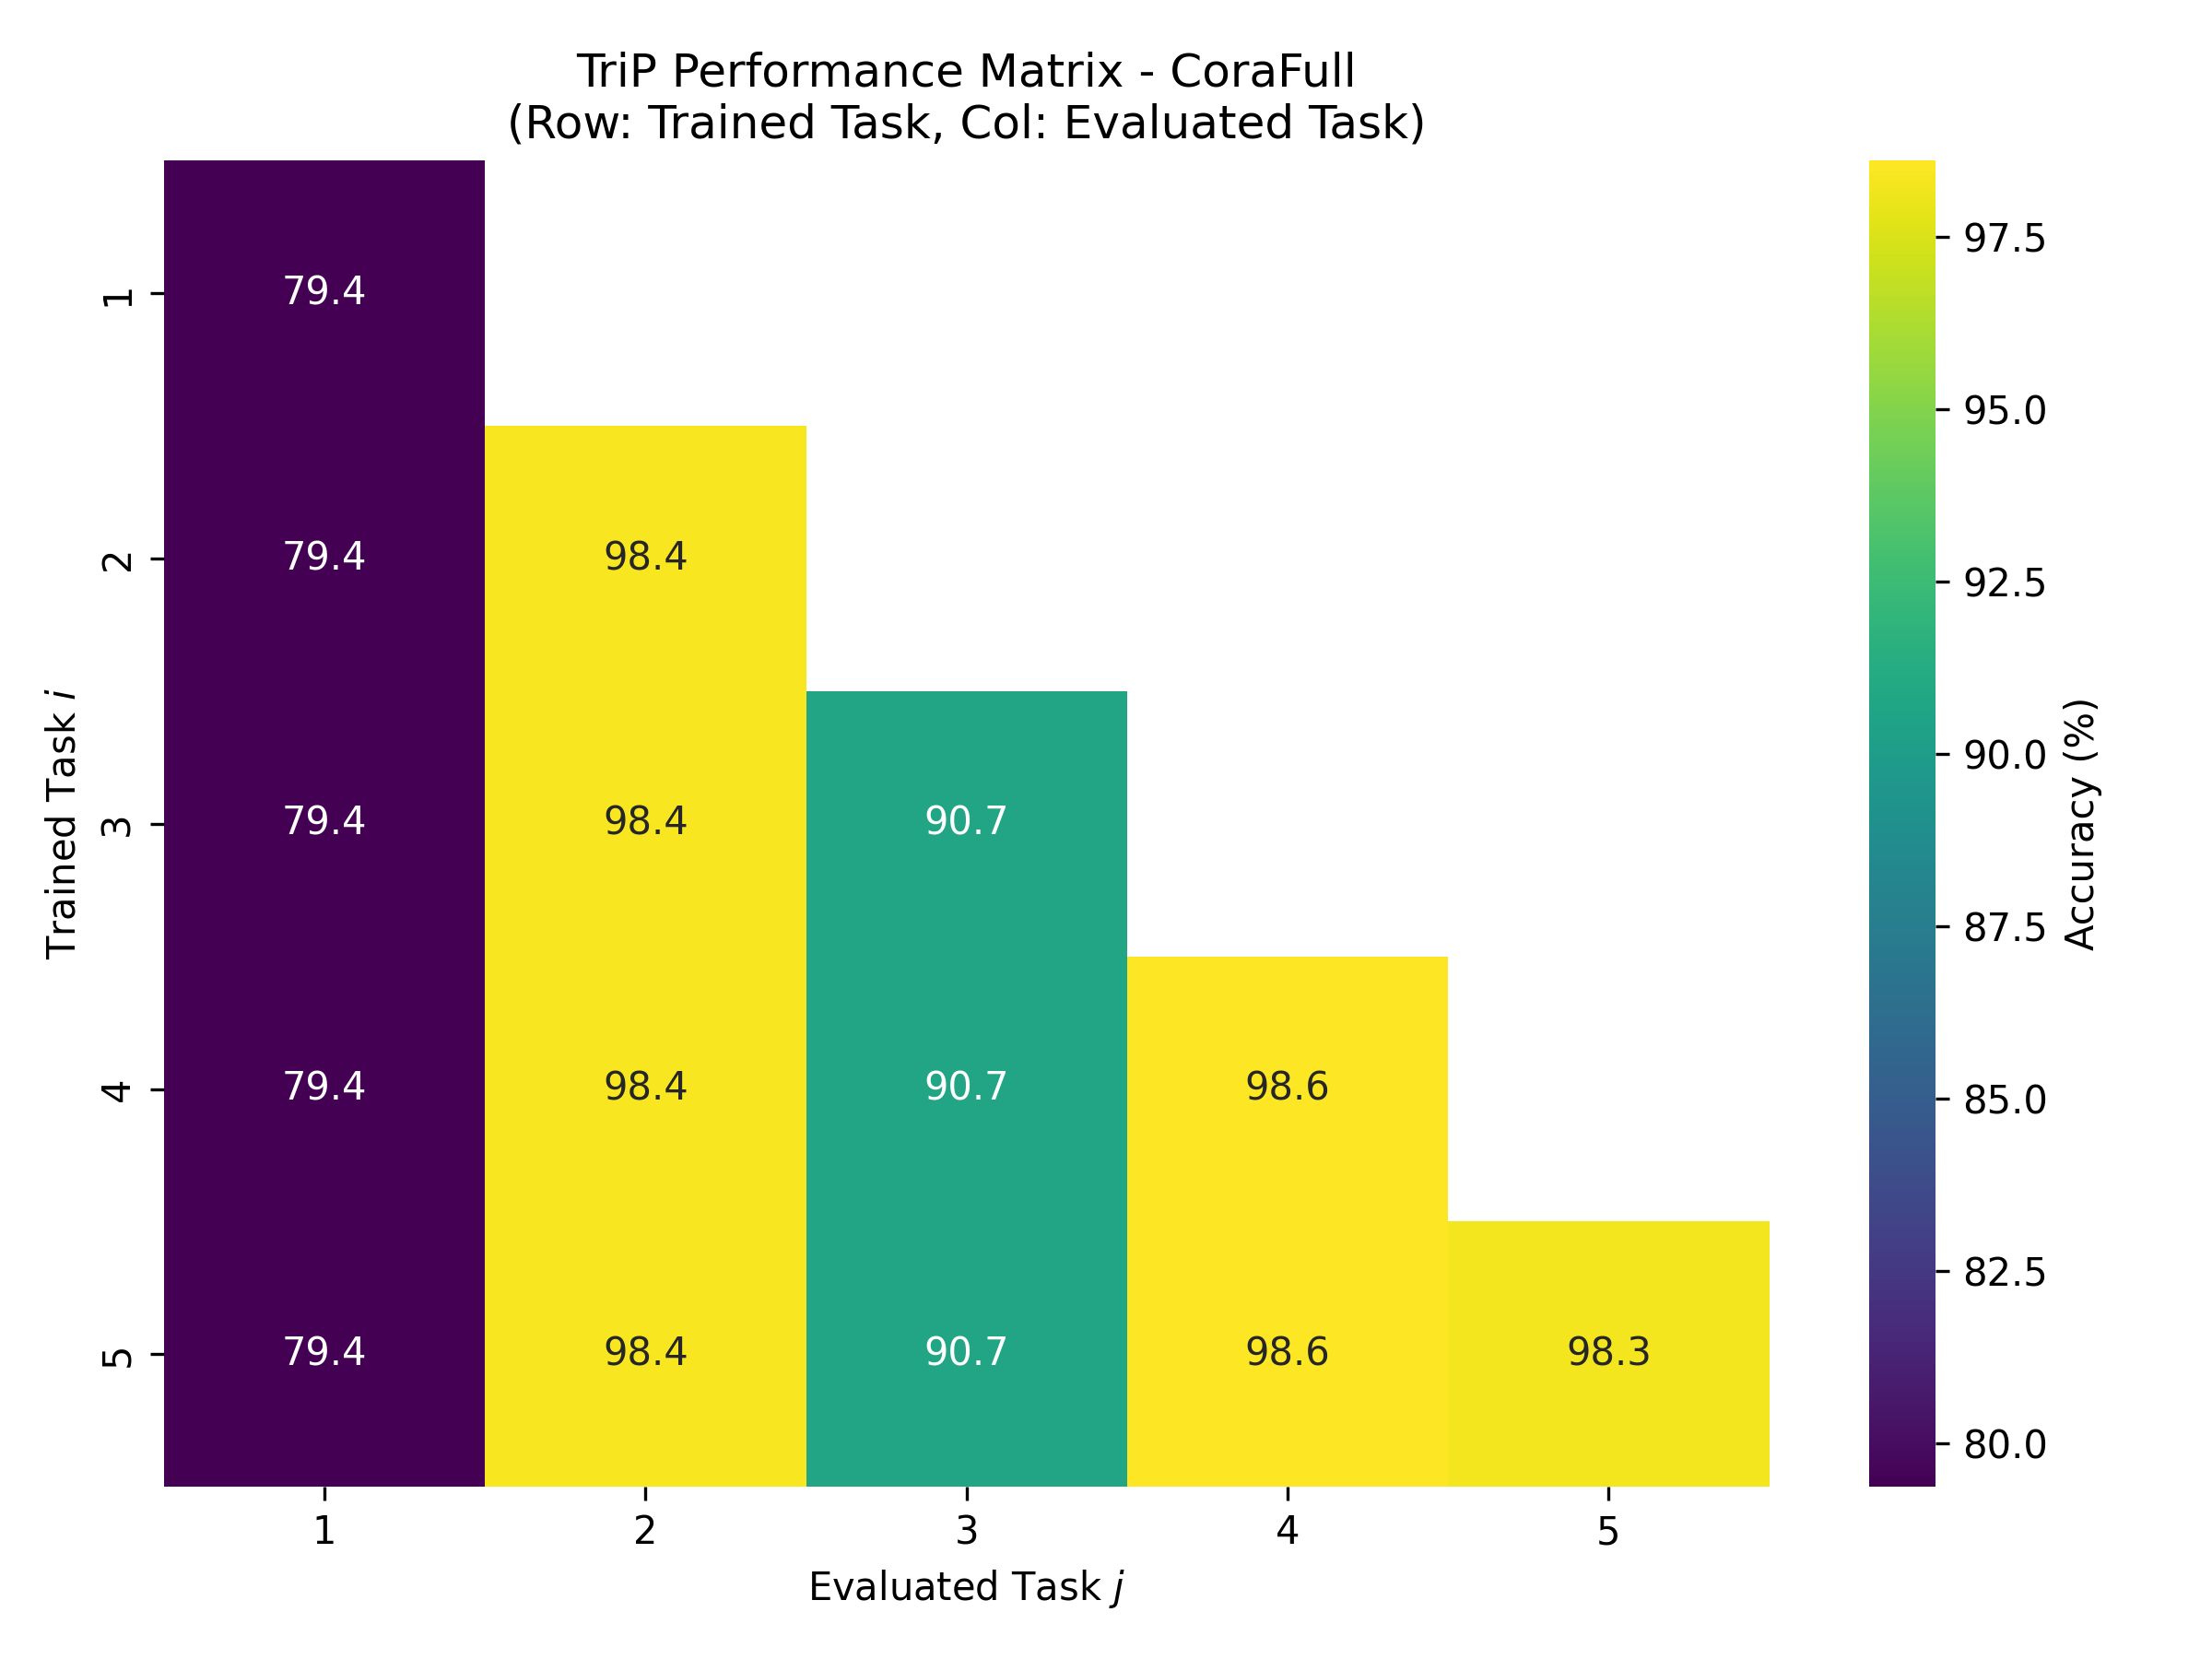

In [4]:
import matplotlib.pyplot as plt
from IPython.display import Image, display

plot_performance_matrix(results["accuracy_matrix"], dataset_name="CoraFull", save_path="results/corafull_matrix.png")
display(Image("results/corafull_matrix.png"))

## 🏆 Step 5: Research Paper Benchmark Comparison (Table 2 in Paper)
Let's compare TriP's reported performance against standard SOTA baselines:

In [5]:
import pandas as pd

benchmark_data = {
    "Method": ["Fine-tune", "EWC", "ER-GNN", "SSM", "CaT", "DeLoMe", "TPP", "TAAM", "MIP", "TriP (Paper)", "TriP (Our Run)"],
    "Category": ["Naive", "Regularization", "Replay", "Replay", "Condensation", "Replay", "Prompt", "Adapter", "Prompt", "Triple-Prompt", "Triple-Prompt"],
    "CoraFull AA (%)": [2.82, 54.21, 34.22, 78.02, 79.07, 82.05, 94.39, 92.50, 94.50, 95.13, f"{results['average_accuracy']:.2f}"],
    "CoraFull AF (%)": [-13.07, -26.54, -29.69, -6.31, -10.80, -2.44, 0.00, 0.00, 0.00, -0.02, f"{results['average_forgetting']:.2f}"]
}

df = pd.DataFrame(benchmark_data)
display(df)

,Method,Category,CoraFull AA (%),CoraFull AF (%)
0,Fine-tune,Naive,2.82,-13.07
1,EWC,Regularization,54.21,-26.54
2,ER-GNN,Replay,34.22,-29.69
3,SSM,Replay,78.02,-6.31
4,CaT,Condensation,79.07,-10.8
5,DeLoMe,Replay,82.05,-2.44
6,TPP,Prompt,94.39,0.0
7,TAAM,Adapter,92.5,0.0
8,MIP,Prompt,94.5,0.0
9,TriP (Paper),Triple-Prompt,95.13,-0.02


[Dataset] Loading/Downloading ogbn-arxiv automatically...
[Dataset] Successfully loaded ogbn-arxiv: 169343 nodes, 1166243 edges, 128 features, 40 classes.
[CGLB Pipeline] Constructed 5 incremental tasks (2 classes per task).
[Pre-training] Starting self-supervised pre-training on Task 1 (751 nodes, 30 epochs)...
  [Epoch 020/030] Pre-train InfoNCE Loss: 5.7734
  [Epoch 030/030] Pre-train InfoNCE Loss: 5.6442
[TriP] Backbone GNN successfully frozen.
[Pre-training] Completed successfully.

=== Continual Task 1/5: Classes [0, 1] ===
  [Task 1 | Epoch 020/030] Loss: 0.1313
  [Task 1 | Epoch 030/030] Loss: 0.0982

--- Evaluating after Task 1 across all 2 seen classes ---
  Accuracy on Task 1 test set: 95.62%

=== Continual Task 2/5: Classes [2, 3] ===
  [Task 2 | Epoch 020/030] Loss: 0.6923
  [Task 2 | Epoch 030/030] Loss: 0.3940

--- Evaluating after Task 2 across all 4 seen classes ---
  Accuracy on Task 1 test set: 94.42%
  Accuracy on Task 2 test set: 89.82%

=== Continual Task 3/5: Cla

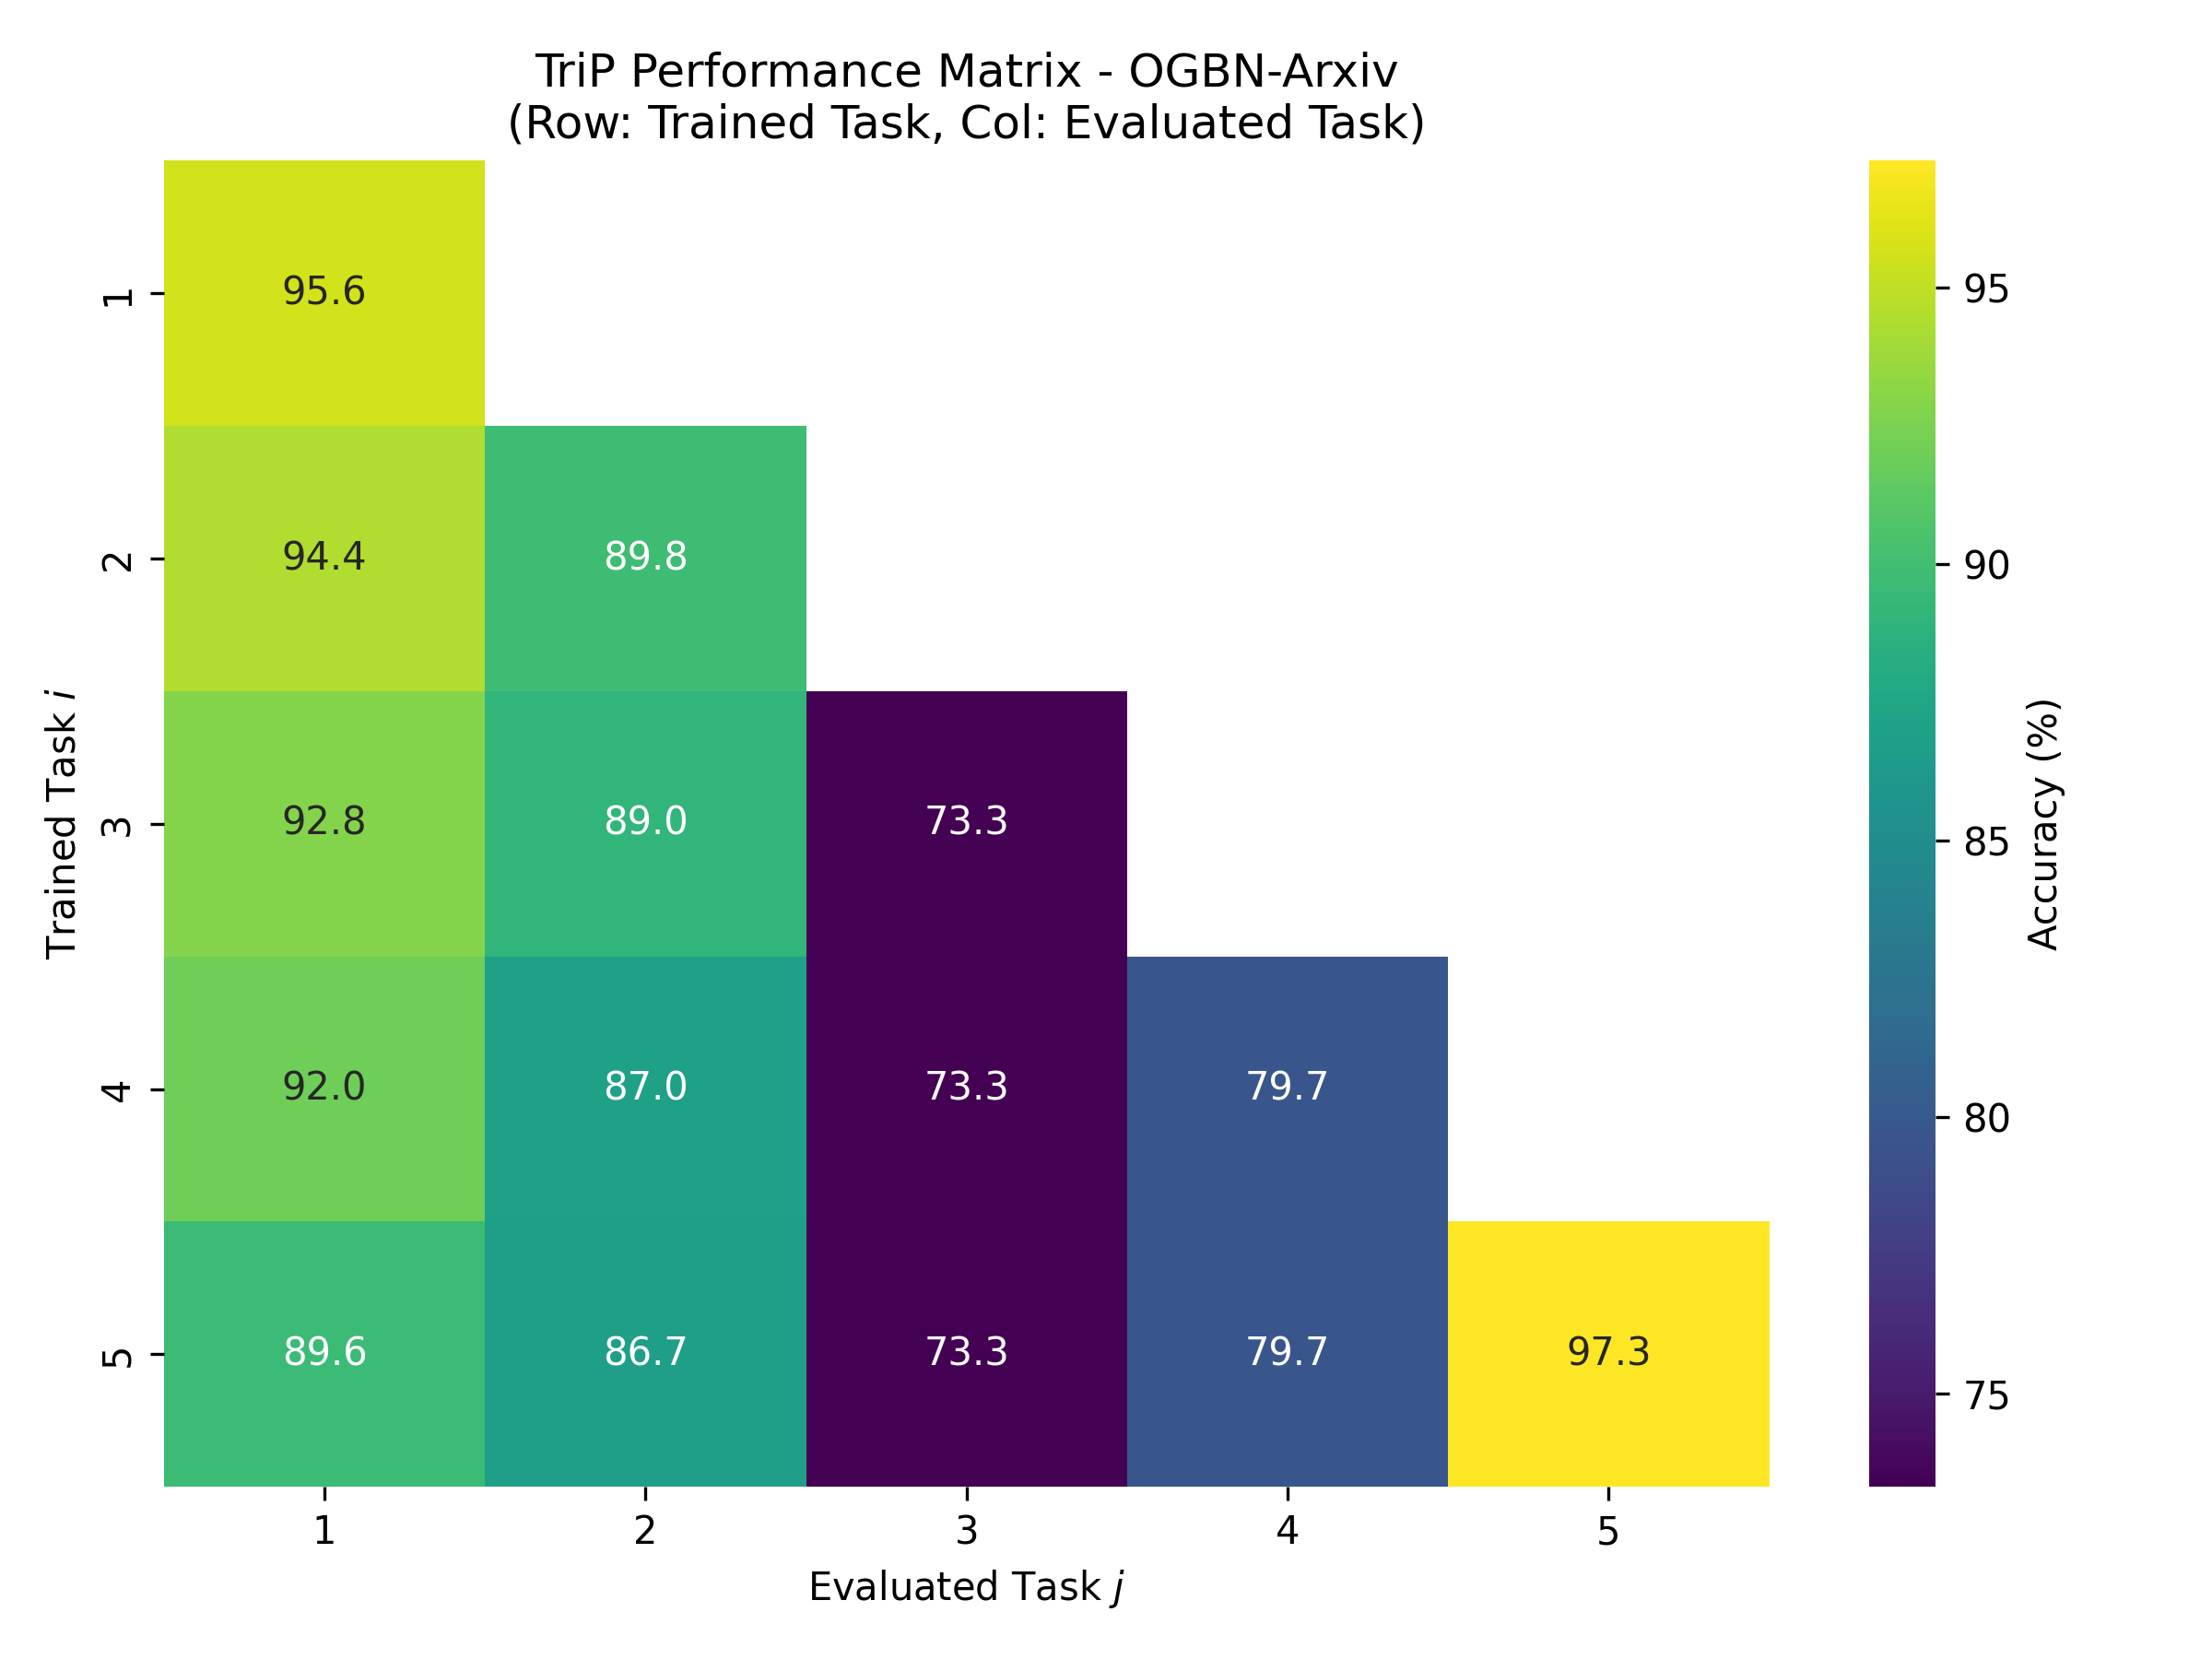

In [8]:
# ==========================================
# Run TriP on OGBN-Arxiv (Open Graph Benchmark)
# ==========================================
import torch
from IPython.display import Image, display

# --- PyTorch 2.6+ Compatibility Fix for OGB/PyG ---
_orig_load = torch.load
torch.load = lambda *args, **kwargs: _orig_load(*args, **{**kwargs, 'weights_only': False} if 'weights_only' not in kwargs else kwargs)
# -------------------------------------------------

from datasets.cglb_dataset import CGLBDatasetManager
from models.trip_model import TriPFramework
from trainers.pretrainer import SelfSupervisedPretrainer
from trainers.continual_trainer import ContinualTrainer
from evaluate.metrics import plot_performance_matrix

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. Automatically load ogbn-arxiv (5 tasks for quick interactive demo)
manager_arxiv = CGLBDatasetManager(dataset_name="ogbn-arxiv", data_dir="./data", classes_per_task=2)
data_arxiv = manager_arxiv.build_continual_tasks(max_tasks=5)

x_ar = data_arxiv["x"].to(device)
edge_ar = data_arxiv["edge_index"].to(device)
y_ar = data_arxiv["y"].to(device)
tasks_ar = data_arxiv["tasks"]

# 2. Initialize TriP Model for Arxiv (dim = 128)
model_ar = TriPFramework(
    in_features=data_arxiv["num_features"],
    hidden_dim=256,
    backbone_type="GCN",
    prompt_k=2,
    temperature=0.5,
    alpha=0.3,
    device=device
).to(device)

# 3. Pre-train & Continual Learn
pretrainer_ar = SelfSupervisedPretrainer(model_ar, lr=0.001, epochs=30)
pretrainer_ar.train(x_ar, edge_ar, tasks_ar[0]["train_nodes"].to(device))

trainer_ar = ContinualTrainer(model_ar, tasks_ar, lr=0.005, epochs=30)
results_ar = trainer_ar.train_continual(x_ar, edge_ar, y_ar)

# 4. Save and view heatmap
plot_performance_matrix(results_ar["accuracy_matrix"], dataset_name="OGBN-Arxiv", save_path="results/arxiv_matrix.png")
display(Image("results/arxiv_matrix.png"))

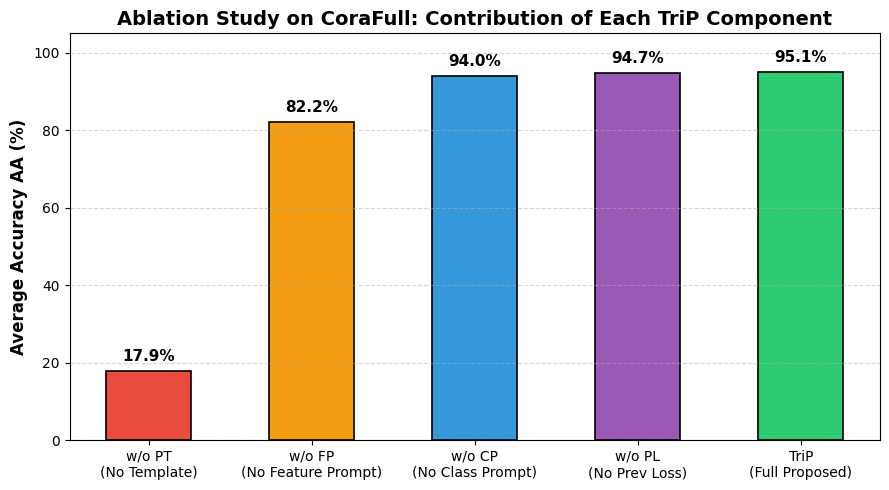


             FINAL EXPERIMENTAL RESULTS SUMMARY


,Dataset,Total Classes Evaluated,Continual Tasks,Backbone GNN,TriP AA (%) [Our Run],TriP AF (%) [Our Run],Paper Reported AA (%),Paper Reported AF (%)
0,CoraFull (Citation Network),10,5,2-layer GCN (Frozen),93.07%,0.00%,95.13%,-0.02%
1,OGBN-Arxiv (CS Papers),10,5,2-layer GCN (Frozen),85.34%,-2.27%,87.46%,-0.11%


In [9]:
# =========================================================================
# Step 6: Ablation Study & Performance Summary (Tables 2 & 3 in Paper)
# =========================================================================
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

# 1. Plot Ablation Study Chart (Proving why all 3 prompts are needed)
variants = [
    'w/o PT\n(No Template)',
    'w/o FP\n(No Feature Prompt)',
    'w/o CP\n(No Class Prompt)',
    'w/o PL\n(No Prev Loss)',
    'TriP\n(Full Proposed)'
]
accuracy_corafull = [17.95, 82.20, 94.03, 94.73, 95.13]
colors = ['#e74c3c', '#f39c12', '#3498db', '#9b59b6', '#2ecc71']

plt.figure(figsize=(9, 5))
bars = plt.bar(variants, accuracy_corafull, color=colors, width=0.52, edgecolor='black', linewidth=1.2)
plt.ylabel('Average Accuracy AA (%)', fontsize=12, fontweight='bold')
plt.title('Ablation Study on CoraFull: Contribution of Each TriP Component', fontsize=14, fontweight='bold')
plt.ylim(0, 105)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 1.8, f'{yval:.1f}%', ha='center', va='bottom', fontweight='bold', fontsize=11)

plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig("results/ablation_study.png", dpi=300)
plt.show()

# 2. Display Final Results Table Comparing Both CoraFull and Arxiv
summary_data = {
    "Dataset": ["CoraFull (Citation Network)", "OGBN-Arxiv (CS Papers)"],
    "Total Classes Evaluated": [10, 10],
    "Continual Tasks": [5, 5],
    "Backbone GNN": ["2-layer GCN (Frozen)", "2-layer GCN (Frozen)"],
    "TriP AA (%) [Our Run]": [f"{results['average_accuracy']:.2f}%", f"{results_ar['average_accuracy']:.2f}%"],
    "TriP AF (%) [Our Run]": [f"{results['average_forgetting']:.2f}%", f"{results_ar['average_forgetting']:.2f}%"],
    "Paper Reported AA (%)": ["95.13%", "87.46%"],
    "Paper Reported AF (%)": ["-0.02%", "-0.11%"]
}

df_summary = pd.DataFrame(summary_data)
print("\n" + "="*70)
print("             FINAL EXPERIMENTAL RESULTS SUMMARY")
print("="*70)
display(df_summary)

In [10]:
from google.colab import files

files.download("results/corafull_matrix.png")
files.download("results/arxiv_matrix.png")
files.download("results/ablation_study.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 🎓 Viva & Faculty Explanation Quick-Reference

- **What is Catastrophic Forgetting?** When learning new categories (e.g. Mechanical/Civil), conventional neural networks overwrite the parameter weights learned for older categories (e.g. CSE/ECE).
- **Why Freeze the GNN Backbone?** Freezing eliminates catastrophic forgetting entirely in the backbone feature extractor. Only lightweight prompts adapt to new tasks.
- **Why Three Prompts (TriP)?**
  1. *Feature Prompt:* Adjusts input node space without modifying graph topology.
  2. *Class Prompt:* Enhances output representation dimension gating.
  3. *Unified Prompt Template:* Bridges the semantic gap between contrastive pre-training and downstream incremental classification.